# XGBoost + environmental-constraint features

Step 2 of the improvement plan. The error analysis (`error_analysis_2022.ipynb`) showed that 42% of the remaining error
is units running although the price is far below the water value, i.e. *forced* operation, with Lio_G1 and Haukeli_G1
the worst units. The extended dataset holds the constraints that can force or block a unit:

| source | features (per case-hour) |
|---|---|
| `Constraint_min_flow.csv`, 6 rivers | minimum flow at hour *t*; maximum requirement during the week |
| `Constraint_min_volume.csv`, 3 reservoirs (Totak, Byrtevatn, Staavatn) | minimum volume at hour *t*; volume at case start minus that minimum; worst-case slack during the week |

Byrtevatn feeds Lio, and the river below Lio is the one with the largest minimum-flow requirement, so both should matter
for the weakest unit. Everything else is identical to `xgboost_price_minus_wv.ipynb` (margin features, honest protocol:
rounds chosen on 2021, score reported on 2022). **Reference: 0.9786.**

In [1]:
# run from the repo root so that data/, results/ and src/ resolve (notebooks live in notebooks/)
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score

from kaggle_metric import score
from train_xgb_baseline import load, FeatureBuilder, H, honest_fit, split_masks, SEED
from features_margin import add_margin_features
from features_constraints import load_constraints, ConstraintFeatures, add_constraint_features

REFERENCE_AUC, REFERENCE_ROUNDS = 0.9786, 222     # margin features only, same protocol
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
BLUE, GREY = "#2a78d6", "#9aa3ad"

def pick_device():
    try:
        xgb.XGBClassifier(n_estimators=1, device="cuda").fit(np.zeros((4, 1)), [0, 1, 0, 1]); return "cuda"
    except Exception:
        return "cpu"
DEVICE = pick_device(); print("training device:", DEVICE)

training device: cuda


## 1. Data and features

In [2]:
uc, price, inflow, volume, water_value = load("data/kernel")
minflow, minvol = load_constraints("data/extended")
test_map = pd.read_csv("prediction_mapping.csv", parse_dates=["starttime"])
sample = pd.read_csv("sample_submission.csv", nrows=1)
label_cols = [c for c in sample.columns if c != "Run No"]
units = list(dict.fromkeys(c.rsplit("_t", 1)[0].replace("result_committed_", "") for c in label_cols))
N_UNITS = len(units)

build_base = FeatureBuilder(price, inflow, volume, water_value)
constraints = ConstraintFeatures(minflow, minvol, volume)

def build_features(starts):
    return add_constraint_features(add_margin_features(build_base(starts)), starts, constraints)

def to_wide(pred_long, run_ids):
    wide = pred_long.reshape(len(run_ids), H, N_UNITS).transpose(0, 2, 1).reshape(len(run_ids), -1)
    out = pd.DataFrame(wide, columns=label_cols); out.insert(0, "Run No", np.asarray(run_ids)); return out

t0 = time.time()
X = build_features(uc["starttime"])
Y = uc[label_cols].to_numpy(dtype=np.int8).reshape(len(uc), N_UNITS, H).transpose(0, 2, 1).reshape(-1, N_UNITS)
new_cols = [c for c in X.columns if c.startswith(("minflow_", "minvol_", "volgap_"))]
print(f"X: {X.shape} ({len(new_cols)} constraint features), NaNs: {int(X.isna().sum().sum())}, built in {time.time() - t0:.1f}s")
X[new_cols].describe().T[["mean", "min", "max"]].round(2)

X: (490896, 133) (21 constraint features), NaNs: 0, built in 0.6s


,mean,min,max
minflow_b_Kjelavatn,0.47,0.30,0.75
minflow_b_Kjelavatn_wkmax,0.48,0.30,0.75
minflow_b_Hyljelihyl,1.06,0.50,2.00
minflow_b_Hyljelihyl_wkmax,1.09,0.50,2.00
minflow_b_Vinjevatn,1.42,1.00,2.00
minflow_b_Vinjevatn_wkmax,1.44,1.00,2.00
minflow_b_Byrtevatn,0.07,0.00,0.20
minflow_b_Byrtevatn_wkmax,0.07,0.00,0.20
minflow_b_Bandak,4.42,4.00,5.00
minflow_b_Bandak_wkmax,4.44,4.00,5.00


In [3]:
# how often is each constraint active in the training cases, and what does Lio do under each min-flow level?
j_lio = units.index("Lio_G1")
lio = pd.DataFrame({"minflow_level": X["minflow_r_Vest_Vassdraget"], "lio_on": Y[:, j_lio],
                    "byrtevatn_gap": X["volgap_Byrtevatn"], "margin_Lio": X["margin_end_Lio"]})
print(lio.groupby("minflow_level")["lio_on"].agg(hours="size", on_share="mean").round(3))
lio["gap_bin"] = pd.cut(lio["byrtevatn_gap"], [-np.inf, 0, 5, 10, 20, 40, np.inf])
lio.groupby("gap_bin", observed=True)["lio_on"].agg(hours="size", on_share="mean").round(3)

                hours  on_share
minflow_level                  
5.0            285264     0.756
8.0            122304     0.656
14.0            83328     0.847


,hours,on_share
gap_bin,,
"(-inf, 0.0]",864,0.440
"(0.0, 5.0]",36288,0.426
"(5.0, 10.0]",29712,0.804
"(10.0, 20.0]",28896,0.508
"(20.0, 40.0]",82320,0.660
"(40.0, inf]",312816,0.824


## 2. Train (rounds on 2021, report on 2022)

In [4]:
params = dict(learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, min_child_weight=5)
t0 = time.time()
res = honest_fit(X, Y, uc["starttime"], params, tune_year=2021, report_year=2022, device=DEVICE)
print(f"rounds chosen on 2021: {res['n_rounds']}  (reference {REFERENCE_ROUNDS})   2021 micro AUC {res['tune_auc']:.4f}")
print(f"2022 report micro ROC AUC: {res['report_auc']:.4f}   (reference {REFERENCE_AUC:.4f}, {res['report_auc'] - REFERENCE_AUC:+.4f})   [{time.time() - t0:.0f}s]")
val_runs = uc.loc[split_masks(uc["starttime"], 2022)[1], "Run No"]
assert abs(score(to_wide(Y[res["val_mask"]], val_runs), to_wide(res["pred"], val_runs)) - res["report_auc"]) < 1e-9

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [10:50:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


rounds chosen on 2021: 229  (reference 222)   2021 micro AUC 0.9766
2022 report micro ROC AUC: 0.9792   (reference 0.9786, +0.0006)   [84s]


In [5]:
reference_per_unit = {"Lio_G1": 0.891, "Haukeli_G1": 0.919, "Vinje_G3": 0.968, "Hogga_G1": 0.973, "Kjela_G1": 0.977,
                      "Vinje_G2": 0.977, "Tokke_G4": 0.982, "Vinje_G1": 0.983, "Vesle Kjela_G1": 0.983, "Tokke_G2": 0.984,
                      "Tokke_G3": 0.988, "Songa_G1": 0.990, "Tokke_G1": 0.993, "Byrte_G1": 0.996}
per_unit = pd.DataFrame({"margin_only": pd.Series(reference_per_unit), "with_constraints": pd.Series(res["per_unit"], index=units)})
per_unit["diff"] = per_unit["with_constraints"] - per_unit["margin_only"]
per_unit.sort_values("with_constraints").round(3)

,margin_only,with_constraints,diff
Lio_G1,0.891,0.912,0.021
Haukeli_G1,0.919,0.915,-0.004
Vinje_G3,0.968,0.967,-0.001
Hogga_G1,0.973,0.974,0.001
Kjela_G1,0.977,0.977,-0.000
Vinje_G2,0.977,0.978,0.001
Tokke_G4,0.982,0.982,0.000
Vinje_G1,0.983,0.983,0.000
Vesle Kjela_G1,0.983,0.983,0.000
Tokke_G2,0.984,0.986,0.002


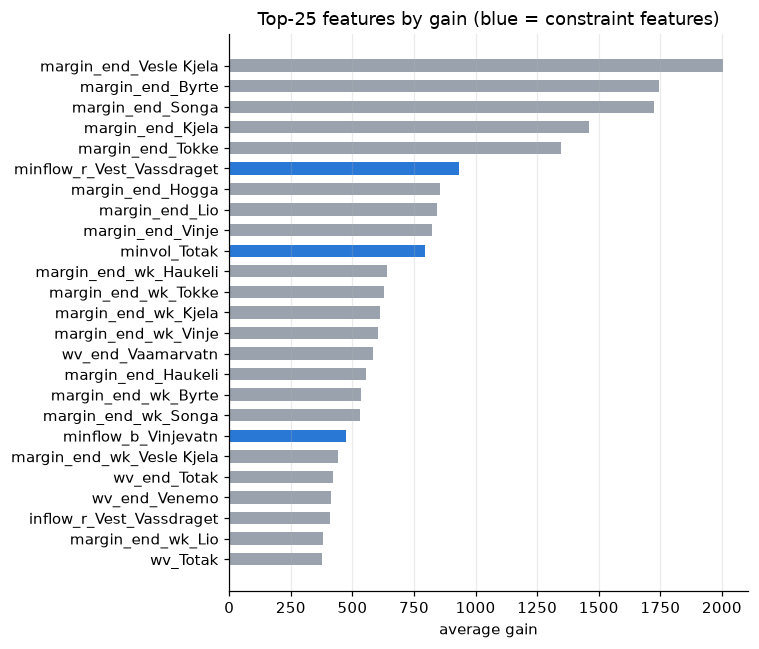

constraint features in the top 25: ['minflow_b_Vinjevatn', 'minvol_Totak', 'minflow_r_Vest_Vassdraget']


In [6]:
imp = pd.Series(res["model"].get_booster().get_score(importance_type="gain")).sort_values()
top = imp.tail(25)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=[BLUE if c in new_cols else GREY for c in top.index], height=0.6)
ax.set_xlabel("average gain"); ax.set_title("Top-25 features by gain (blue = constraint features)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("constraint features in the top 25:", [c for c in top.index if c in new_cols])

## 3. Refit on all years and write the submission

In [7]:
t0 = time.time()
final_model = xgb.XGBClassifier(n_estimators=res["n_rounds"], tree_method="hist", device=DEVICE, random_state=SEED, **params).fit(X, Y)
print(f"refit on {len(uc)} cases with {res['n_rounds']} rounds in {time.time() - t0:.0f}s")
X_test = build_features(test_map["starttime"])
assert list(X_test.columns) == list(X.columns) and int(X_test.isna().sum().sum()) == 0
submission = to_wide(final_model.predict_proba(X_test), test_map["Run No"])
assert list(submission.columns) == list(sample.columns)
vals = submission[label_cols].to_numpy(); assert ((vals >= 0) & (vals <= 1)).all()
fname = f"submission_xgb_constraints_cv{res['report_auc']:.4f}.csv"
submission.to_csv(fname, index=False); print("saved", fname, submission.shape)

refit on 2922 cases with 229 rounds in 39s


saved submission_xgb_constraints_cv0.9792.csv (725, 2353)
